In [149]:
import pandas as pd


from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

from matplotlib.pyplot import matplotlib as plt


In [150]:
df = pd.read_csv(r"C:\Users\SART\Desktop\Practise\csvs\Pakwheel Data.csv")
df.head()

,Unnamed: 0,Title,Model,CC,Engine_type,Transmission,Km_Driven,prices
0,0,Honda Vezel 2019 Hybrid Z Honda Sensing for ...,2019,1500 cc,Petrol,Automatic,"26,755 km",72.50
1,1,Suzuki Wagon R 2020 Hybrid FX for Sale,2020,660 cc,Hybrid,Automatic,"9,744 km",32.50
2,2,Toyota Corolla Axio 2008 G Kurashiko for Sale,2008,1500 cc,Petrol,Automatic,"85,000 km",29.80
3,3,Toyota Corolla 2018 XLi VVTi for Sale,2018,1300 cc,Petrol,Manual,"40,000 km",33.25
4,4,Daihatsu Mira 2020 G SA III for Sale,2020,660 cc,Petrol,Automatic,"23,300 km",35.75


In [151]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 60555 entries, 0 to 60554
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0    60555 non-null  int64  
 1   Title         60555 non-null  str    
 2   Model         60555 non-null  int64  
 3   CC            60555 non-null  str    
 4   Engine_type   60555 non-null  str    
 5   Transmission  60555 non-null  str    
 6   Km_Driven     60555 non-null  str    
 7   prices        59556 non-null  float64
dtypes: float64(1), int64(2), str(5)
memory usage: 3.7 MB


In [152]:
df['prices'].isnull().sum()

np.int64(999)

In [153]:
df['prices'].mean()

np.float64(31.958114379743435)

In [154]:
df['prices'] = df['prices'].fillna(df['prices'].mean())

In [155]:
df['prices'].isnull().sum()

np.int64(0)

In [156]:
df['CC'].head()


0    1500 cc
1     660 cc
2    1500 cc
3    1300 cc
4     660 cc
Name: CC, dtype: str

In [157]:
df['CC'] = df['CC'].str.replace(' cc', '')

In [158]:
df['CC'].head()

0    1500
1     660
2    1500
3    1300
4     660
Name: CC, dtype: str

In [159]:
df['Km_Driven'] = df['Km_Driven'].str.replace(',', '')

In [160]:
df['Km_Driven']

0        26755 km
1         9744 km
2        85000 km
3        40000 km
4        23300 km
           ...   
60550     1400 km
60551    94000 km
60552    75000 km
60553    23295 km
60554    38847 km
Name: Km_Driven, Length: 60555, dtype: str

In [161]:
df['Km_Driven'] = df['Km_Driven'].str.replace('km', '')

In [162]:
df['Km_Driven']

0        26755 
1         9744 
2        85000 
3        40000 
4        23300 
          ...  
60550     1400 
60551    94000 
60552    75000 
60553    23295 
60554    38847 
Name: Km_Driven, Length: 60555, dtype: str

In [163]:
df['Km_Driven'] = pd.to_numeric(df['Km_Driven'])

In [164]:
df['Km_Driven']

0        26755
1         9744
2        85000
3        40000
4        23300
         ...  
60550     1400
60551    94000
60552    75000
60553    23295
60554    38847
Name: Km_Driven, Length: 60555, dtype: int64

In [165]:
df['Title'].head()

0    Honda Vezel  2019 Hybrid Z Honda Sensing  for ...
1              Suzuki Wagon R  2020 Hybrid FX for Sale
2       Toyota Corolla Axio  2008 G Kurashiko for Sale
3               Toyota Corolla  2018 XLi VVTi for Sale
4                Daihatsu Mira  2020 G SA III for Sale
Name: Title, dtype: str

In [166]:
df['CarName'] = df['Title'].str.split('\d{4}').str[0].str.strip()

<>:1: SyntaxWarning: invalid escape sequence '\d'
<>:1: SyntaxWarning: invalid escape sequence '\d'
C:\Users\SART\AppData\Local\Temp\ipykernel_12016\2034751572.py:1: SyntaxWarning: invalid escape sequence '\d'
  df['CarName'] = df['Title'].str.split('\d{4}').str[0].str.strip()


In [167]:
df['CarName']

0                Honda Vezel
1             Suzuki Wagon R
2        Toyota Corolla Axio
3             Toyota Corolla
4              Daihatsu Mira
                ...         
60550             Honda City
60551             Honda City
60552         Suzuki Wagon R
60553          Daihatsu Move
60554            Honda N Wgn
Name: CarName, Length: 60555, dtype: object

In [168]:
df.head()

,Unnamed: 0,Title,Model,CC,Engine_type,Transmission,Km_Driven,prices,CarName
0,0,Honda Vezel 2019 Hybrid Z Honda Sensing for ...,2019,1500,Petrol,Automatic,26755,72.50,Honda Vezel
1,1,Suzuki Wagon R 2020 Hybrid FX for Sale,2020,660,Hybrid,Automatic,9744,32.50,Suzuki Wagon R
2,2,Toyota Corolla Axio 2008 G Kurashiko for Sale,2008,1500,Petrol,Automatic,85000,29.80,Toyota Corolla Axio
3,3,Toyota Corolla 2018 XLi VVTi for Sale,2018,1300,Petrol,Manual,40000,33.25,Toyota Corolla
4,4,Daihatsu Mira 2020 G SA III for Sale,2020,660,Petrol,Automatic,23300,35.75,Daihatsu Mira


In [169]:
df.columns

Index(['Unnamed: 0', 'Title', 'Model', 'CC', 'Engine_type', 'Transmission',
       'Km_Driven', 'prices', 'CarName'],
      dtype='str')

In [170]:
df.drop(columns=['Unnamed: 0', 'Title'], inplace=True)

In [171]:
df.head()

,Model,CC,Engine_type,Transmission,Km_Driven,prices,CarName
0,2019,1500,Petrol,Automatic,26755,72.50,Honda Vezel
1,2020,660,Hybrid,Automatic,9744,32.50,Suzuki Wagon R
2,2008,1500,Petrol,Automatic,85000,29.80,Toyota Corolla Axio
3,2018,1300,Petrol,Manual,40000,33.25,Toyota Corolla
4,2020,660,Petrol,Automatic,23300,35.75,Daihatsu Mira


In [172]:
a = df['Model'].value_counts()

print(a)

b = a.index
o = a.values

print(o[:10])
print(b[:10])

Model
2021    5238
2018    4886
2020    4851
2022    4401
2017    3465
        ... 
1951       2
1942       2
1969       2
1945       1
1958       1
Name: count, Length: 69, dtype: int64
[5238 4886 4851 4401 3465 3313 2746 2644 2632 2235]
Index([2021, 2018, 2020, 2022, 2017, 2019, 2015, 2016, 2014, 2007], dtype='int64', name='Model')


In [173]:
plt.pie()

AttributeError: module 'matplotlib' has no attribute 'pie'

In [174]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

# Ensure numeric data types
df['CC'] = pd.to_numeric(df['CC'], errors='coerce')
df['Km_Driven'] = pd.to_numeric(df['Km_Driven'], errors='coerce')
df['Model'] = pd.to_numeric(df['Model'], errors='coerce')
df['prices'] = pd.to_numeric(df['prices'], errors='coerce')


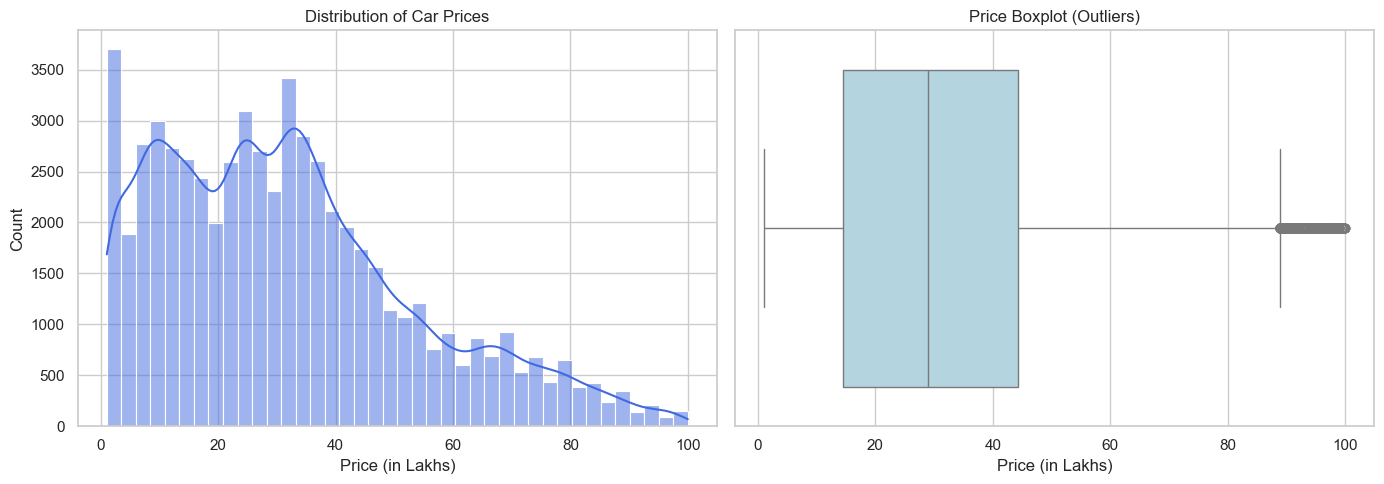

In [175]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram / KDE
sns.histplot(df['prices'], kde=True, bins=40, color='royalblue', ax=axes[0])
axes[0].set_title('Distribution of Car Prices')
axes[0].set_xlabel('Price (in Lakhs)')
axes[0].set_ylabel('Count')

# Boxplot to spot luxury outliers
sns.boxplot(x=df['prices'], color='lightblue', ax=axes[1])
axes[1].set_title('Price Boxplot (Outliers)')
axes[1].set_xlabel('Price (in Lakhs)')

plt.tight_layout()
plt.show()


C:\Users\SART\AppData\Local\Temp\ipykernel_12016\267945139.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10_cars.values, y=top_10_cars.index, palette='Blues_r', ax=axes[0])
C:\Users\SART\AppData\Local\Temp\ipykernel_12016\267945139.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=avg_price_top_10.values, y=avg_price_top_10.index, palette='Greens_r', ax=axes[1])


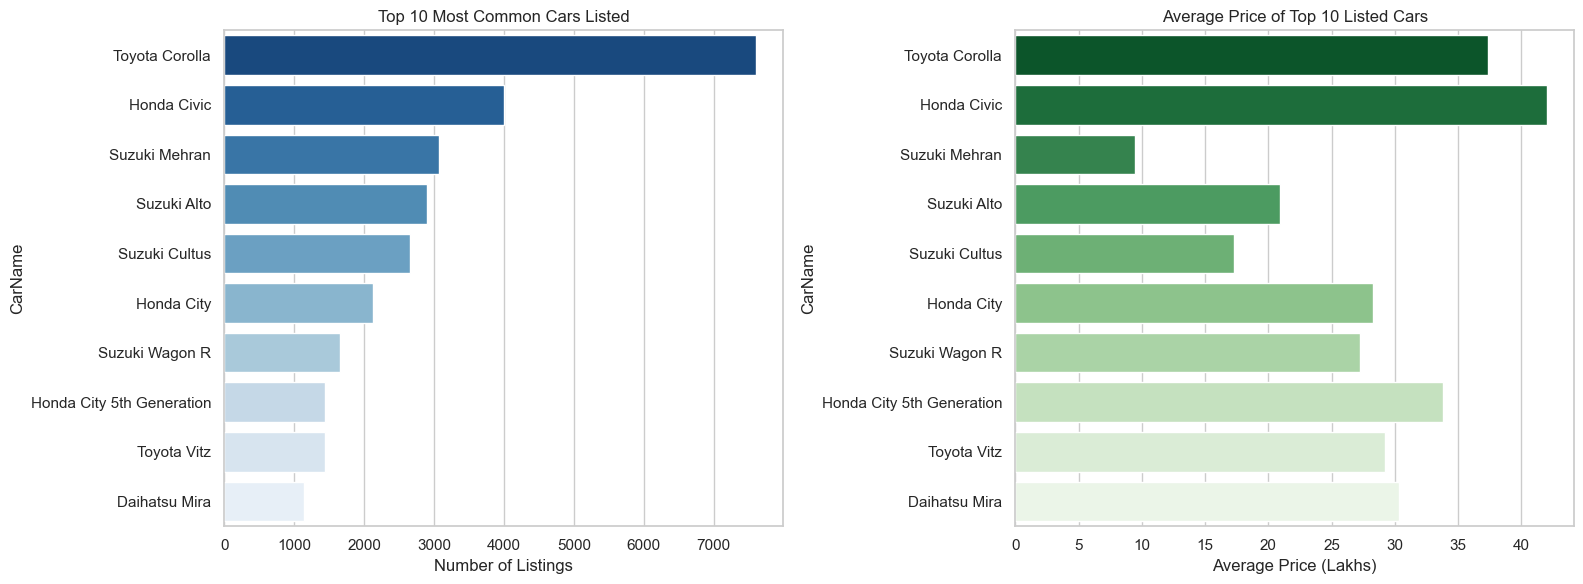

In [176]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Top 10 most frequent cars
top_10_cars = df['CarName'].value_counts().head(10)
sns.barplot(x=top_10_cars.values, y=top_10_cars.index, palette='Blues_r', ax=axes[0])
axes[0].set_title('Top 10 Most Common Cars Listed')
axes[0].set_xlabel('Number of Listings')

# Average price of the top 10 cars
avg_price_top_10 = df[df['CarName'].isin(top_10_cars.index)].groupby('CarName')['prices'].mean().reindex(top_10_cars.index)
sns.barplot(x=avg_price_top_10.values, y=avg_price_top_10.index, palette='Greens_r', ax=axes[1])
axes[1].set_title('Average Price of Top 10 Listed Cars')
axes[1].set_xlabel('Average Price (Lakhs)')

plt.tight_layout()
plt.show()


In [177]:
lb = LabelEncoder()

In [178]:
from sklearn.preprocessing import LabelEncoder

# 1. Create separate encoders
le_engine = LabelEncoder()
le_trans = LabelEncoder()
le_car = LabelEncoder()

# 2. Fit and transform each column
df['Engine_type'] = le_engine.fit_transform(df['Engine_type'])
df['Transmission'] = le_trans.fit_transform(df['Transmission'])
df['CarName'] = le_car.fit_transform(df['CarName'])


In [179]:
df.head()

,Model,CC,Engine_type,Transmission,Km_Driven,prices,CarName
0,2019,1500.0,5,0,26755,72.50,177
1,2020,660.0,3,0,9744,32.50,437
2,2008,1500.0,5,0,85000,29.80,468
3,2018,1300.0,5,1,40000,33.25,465
4,2020,660.0,5,0,23300,35.75,89


In [103]:
sc = StandardScaler()

In [183]:
df_num = df.select_dtypes(include=['number'])

df_num.head()


,Model,CC,Engine_type,Transmission,Km_Driven,prices,CarName
0,2019,1500.0,5,0,26755,72.50,177
1,2020,660.0,3,0,9744,32.50,437
2,2008,1500.0,5,0,85000,29.80,468
3,2018,1300.0,5,1,40000,33.25,465
4,2020,660.0,5,0,23300,35.75,89


In [184]:
df = df.dropna()

In [185]:
X = df[['Model','CC','Engine_type',	'Transmission',	'Km_Driven', 'CarName']]
y = df['prices']

In [186]:
X['CC'].isnull().sum()

np.int64(0)

In [187]:
df.isnull().sum()

Model           0
CC              0
Engine_type     0
Transmission    0
Km_Driven       0
prices          0
CarName         0
dtype: int64

In [188]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20)

In [189]:
print(X_train)

       Model      CC  Engine_type  Transmission  Km_Driven  CarName
18088   2020  1200.0            3             0      65500      341
21499   2012   800.0            5             1      80000      402
56670   2017  1600.0            5             0        123      465
20595   2011  1300.0            5             1     123456      465
39028   2018  1800.0            3             0      66000      455
...      ...     ...          ...           ...        ...      ...
54547   2018  1500.0            5             0     118000      144
543     2012  1600.0            5             0      97123      465
33208   2009  1000.0            0             1          2      399
57361   2008   800.0            5             1         18      423
11287   2011  1500.0            5             0      12345      331

[48038 rows x 6 columns]


In [190]:
print(y_train)

18088    52.50
21499     7.00
56670    38.00
20595    23.50
39028    84.50
         ...  
54547    36.80
543      28.75
33208     9.30
57361     8.20
11287    28.45
Name: prices, Length: 48038, dtype: float64


In [191]:
model = LinearRegression()

In [192]:
print(X_train.isnull().sum())

Model           0
CC              0
Engine_type     0
Transmission    0
Km_Driven       0
CarName         0
dtype: int64


In [193]:
print(X_test.isnull().sum())

Model           0
CC              0
Engine_type     0
Transmission    0
Km_Driven       0
CarName         0
dtype: int64


In [194]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](6,)","[ 0.87, 0. , -0.87,-14.76, -0. , -0.01]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](6,)","['Model','CC','Engine_type','Transmission','Km_Driven','CarName']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1712
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(6)


In [195]:
y_pred = model.predict(X_test)
print(y_pred)

[47.36765667 43.5752836  19.33191479 ... 13.6433353  39.37547229
 38.00635627]


In [196]:
mse = mean_squared_error(y_test, y_pred)
print(mse)

310.1176101452774


In [197]:
import pandas as pd

def predict_user_car():
    print("--- 🚗 PakWheels Car Price Predictor ---")
    
    # 1. Take inputs from user
    model_year = int(input("Enter Model Year (e.g., 2019): "))
    cc = float(input("Enter Engine Capacity in CC (e.g., 1500): "))
    
    # Engine type
    print("Engine Type options -> Petrol: 5 | Hybrid: 3 | Diesel: 1")
    engine_type = int(input("Enter Engine Type code: "))
    
    # Transmission
    print("Transmission options -> Automatic: 0 | Manual: 1")
    transmission = int(input("Enter Transmission code: "))
    
    km_driven = float(input("Enter Kilometers Driven (e.g., 35000): "))
    car_name_code = int(input("Enter CarName encoded code (e.g., 177 for Vezel): "))
    
    # 2. Put into a DataFrame with exact column names used in training
    user_data = pd.DataFrame({
        'Model': [model_year],
        'CC': [cc],
        'Engine_type': [engine_type],
        'Transmission': [transmission],
        'Km_Driven': [km_driven],
        'CarName': [car_name_code]
    })
    
    # 3. Predict price
    predicted_price = model.predict(user_data)[0]
    
    # 4. Display result
    print("\n-------------------------------------------")
    print(f"💰 Estimated Price: {predicted_price:.2f} Lakhs")
    print(f"   (Approx. PKR {predicted_price * 100000:,.0f})")
    print("-------------------------------------------")

# Run the function
predict_user_car()

--- 🚗 PakWheels Car Price Predictor ---
Engine Type options -> Petrol: 5 | Hybrid: 3 | Diesel: 1


ValueError: invalid literal for int() with base 10: 'Manual'

In [201]:
import pandas as pd

def predict_user_car():
    print("--- 🚗 PakWheels Car Price Predictor ---")
    
    # 1. Numeric inputs
    model_year = int(input("Enter Model Year (e.g., 2019): "))
    cc = float(input("Enter Engine Capacity in CC (e.g., 1500): "))
    
    # 2. Engine type (accepts name or number)
    engine_dict = {
        'petrol': 5, 'hybrid': 3, 'diesel': 1,
        '5': 5, '3': 3, '1': 1
    }
    print("\nEngine options: Petrol (5), Hybrid (3), Diesel (1)")
    eng_input = input("Enter Engine Type: ").strip().lower()
    engine_type = engine_dict.get(eng_input, 5)
    
    # 3. Transmission (accepts name or number)
    trans_dict = {
        'automatic': 0, 'auto': 0, '0': 0,
        'manual': 1, '1': 1
    }
    print("\nTransmission options: Automatic (0) or Manual (1)")
    trans_input = input("Enter Transmission: ").strip().lower()
    transmission = trans_dict.get(trans_input, 0)
    
    km_driven = float(input("\nEnter Kilometers Driven (e.g., 35000): "))
    
    # 4. Car Name
    print("\nCommon Car Codes: Vezel: 177 | Wagon R: 437 | Corolla: 465 | Axio: 468 | Mira: 89")
    car_input = input("Enter Car Name or Code: ").strip()
    
    if car_input.isdigit():
        car_name_code = int(car_input)
    elif hasattr(lb, 'classes_'):
        matches = [i for i, name in enumerate(lb.classes_) if car_input.lower() in str(name).lower()]
        if matches:
            car_name_code = matches[0]
            print(f"   -> Matched to '{lb.classes_[car_name_code]}' (code {car_name_code})")
        else:
            print(f"   ⚠️ Name not found. Using default code 177.")
            car_name_code = 177
    else:
        print("   ⚠️ Encoder not fitted. Using default code 177 (Honda Vezel).")
        car_name_code = 177
    
    # 5. Prepare DataFrame
    user_data = pd.DataFrame({
        'Model': [model_year],
        'CC': [cc],
        'Engine_type': [engine_type],
        'Transmission': [transmission],
        'Km_Driven': [km_driven],
        'CarName': [car_name_code]
    })
    
    # 6. Predict price
    predicted_price = model.predict(user_data)[0]
    
    # 7. Display result
    print("\n" + "="*45)
    print(f"💰 Estimated Price: {predicted_price:.2f} Lakhs")
    print(f"   (Approx. PKR {predicted_price * 100000:,.0f})")
    print("="*45)

# Run the function
predict_user_car()


--- 🚗 PakWheels Car Price Predictor ---

Engine options: Petrol (5), Hybrid (3), Diesel (1)

Transmission options: Automatic (0) or Manual (1)

Common Car Codes: Vezel: 177 | Wagon R: 437 | Corolla: 465 | Axio: 468 | Mira: 89
   ⚠️ Encoder not fitted. Using default code 177 (Honda Vezel).

💰 Estimated Price: 32.00 Lakhs
   (Approx. PKR 3,199,900)
